In [9]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.1


In [23]:
train = pd.read_csv("FNN and CNN/CIFAR10/cifar-10.csv")

print("Dataset shape:", train.shape)
train.head()

Dataset shape: (50000, 3073)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [24]:
x = train.drop("label", axis=1).values
y = train["label"].values

print("Features shape:", x.shape)
print("Labels shape:", y.shape)
print("Unique labels:", np.unique(y))

Features shape: (50000, 3072)
Labels shape: (50000,)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [25]:
x = x.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)

x = x.astype("float32") / 255.0

print("Image shape:", x.shape)

Image shape: (50000, 32, 32, 3)


In [26]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


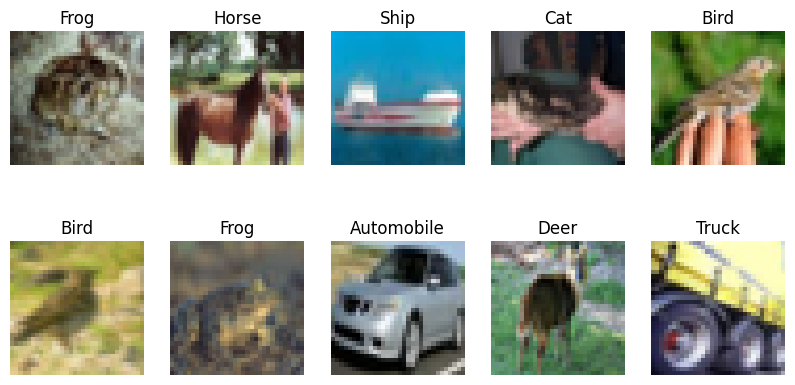

In [27]:
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.show()

In [28]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [29]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.4441 - loss: 1.5437 - val_accuracy: 0.5301 - val_loss: 1.3068
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.5784 - loss: 1.1902 - val_accuracy: 0.5836 - val_loss: 1.1873
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.6381 - loss: 1.0315 - val_accuracy: 0.6285 - val_loss: 1.0687
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6722 - loss: 0.9358 - val_accuracy: 0.6529 - val_loss: 1.0056
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7031 - loss: 0.8544 - val_accuracy: 0.6711 - val_loss: 0.9599
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7299 - loss: 0.7792 - val_accuracy: 0.6776 - val_loss: 0.9398
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7501 - loss: 0.7171 - val_accuracy: 0.6731 - val_loss: 0.9559
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7711 - loss: 0.6572 - 

In [31]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6869 - loss: 0.9698
Test Loss: 0.9697906374931335
Test Accuracy: 0.6869000196456909


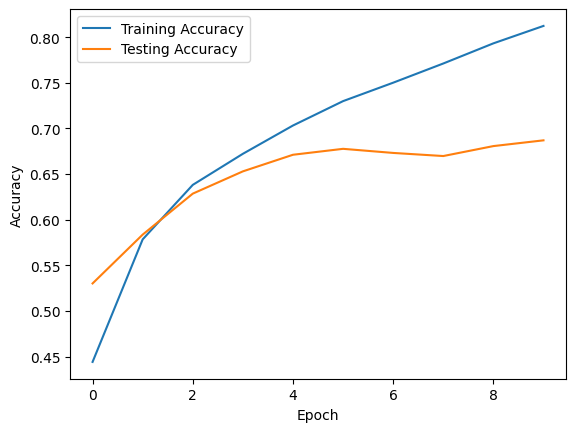

In [32]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Testing Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

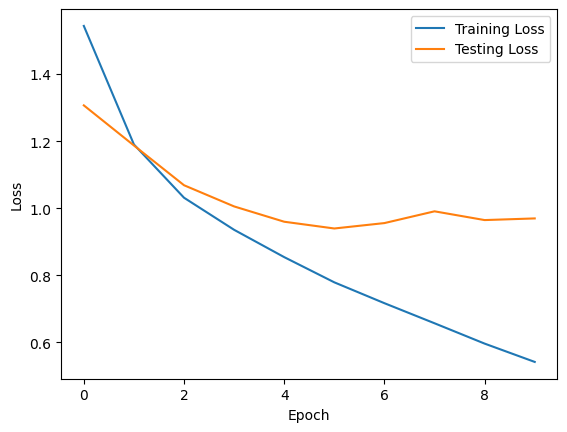

In [33]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [34]:
y_pred = model.predict(x_test)
y_pred = np.argmax(y_pred, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Confusion Matrix:
[[701  38  41  18  20  15   6  21  94  46]
 [ 23 782   1   8   8   8   7  10  29 124]
 [ 73  15 529  82  96  79  42  50  19  15]
 [ 18  11  54 505  57 220  47  47  14  27]
 [ 14   4  87  65 624  52  35  92  13  14]
 [ 16   7  46 163  46 613  21  65  12  11]
 [ 10  12  52  88  45  43 722  11   5  12]
 [  9   6  21  46  54  74   5 756   7  22]
 [ 48  34  14  11   4   8   7   7 832  35]
 [ 26  77   9  17   3  12   4  16  31 805]]

Classification Report:
              precision    recall  f1-score   support

    Airplane       0.75      0.70      0.72      1000
  Automobile       0.79      0.78      0.79      1000
        Bird       0.62      0.53      0.57      1000
         Cat       0.50      0.51      0.50      1000
        Deer       0.65      0.62      0.64      1000
         Dog       0.55      0.61      0.58      1000
        Frog       0.81      0.72      0.76      1000
       Horse       0.70      0.76      0.73      1000

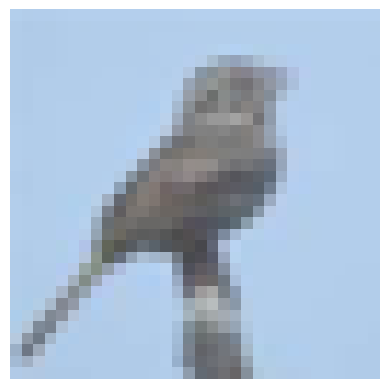

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Actual: Bird
Predicted: Bird


In [35]:
index = 0

plt.imshow(x_test[index])
plt.axis("off")
plt.show()

prediction = model.predict(x_test[index].reshape(1, 32, 32, 3))

print("Actual:", class_names[y_test[index]])
print("Predicted:", class_names[np.argmax(prediction)])